# Manipulating Molecules with RDKit

<div style="background-color: #DCEEFF; padding: 20px; border-radius: 12px;">

    
## Overview

In this notebook, we will use **RDKit** to load, visualize, and manipulate molecular structures. We will also learn how **SMILES** strings represent chemical structures and how molecules can be modified computationally.

### Questions

* How can we load molecular files using RDKit?
* How can we manipulate an existing molecule?
* How can we create and save a modified molecule?

### Objectives

* Understand the Python libraries used in this notebook.
* Learn how **SMILES** represent chemical structures.
* Modify a ligand, such as its **stereochemistry or protonation state**.
* Save the modified ligand for downstream applications such as **molecular docking**.


<img src="images/pyrimethamine1.png" width="400">

## Retrieving and Modifying Pyrimethamine

In this section, we will obtain **pyrimethamine** from **PubChem** and use it as the starting structure for our molecular manipulation exercise.

The approach will be **manual and hands-on**. We will visually identify atoms of interest and modify their atomic numbers to create a new molecular structure. For example, we will:

* Change a **carbon atom into a nitrogen atom**.
* Add a **methyl group** by replacing a hydrogen atom with a carbon atom.
* Examine the resulting molecular structure and its geometry.

We will use an **ideal 3D structure** as our starting point. Because the structure already contains reasonable three-dimensional coordinates, the modified molecule should begin relatively close to a favorable geometry. This increases the likelihood that subsequent **geometry optimization** will converge successfully.

**Workflow:**

**PubChem → Download Pyrimethamine → Load 3D Structure → Identify Atoms → Modify Structure → Optimize Geometry**


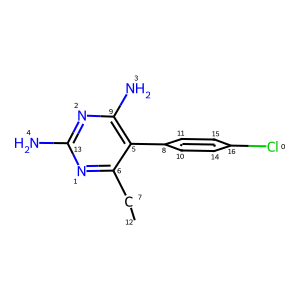

In [11]:
from rdkit import Chem
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Draw

# Configuration for displaying in Jupyter notebooks
IPythonConsole.ipython_useSVG = True  # Use SVG for higher quality images
IPythonConsole.drawOptions.addAtomIndices = True  # Show atom indices
IPythonConsole.molSize = 300,300 # Set size of image

ligand = Chem.MolFromMolFile("ligands/pyrimethamine.sdf")
ligand

## Calculate Molecular Weight and LogP
<div style="background-color: #DCEEFF; padding: 20px; border-radius: 12px;">

**Molecular Weight (MW)** and **LogP** are important properties when evaluating compounds for drug discovery and molecular docking.

* **Molecular Weight (MW):** Indicates the size of a molecule. Very large molecules may have reduced solubility, permeability, and bioavailability.
* **LogP:** Measures the lipophilicity of a compound. It helps indicate how readily a molecule may interact with lipid environments and cross biological membranes.

Together, MW and LogP provide a quick assessment of a compound's **drug-likeness, permeability, and physicochemical properties** before further ADMET analysis and molecular docking.


In [12]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen

# Load ligand
mol = Chem.MolFromMolFile("ligands/pyrimethamine.sdf")

# Calculate properties
molecular_weight = Descriptors.MolWt(mol)
logP = Crippen.MolLogP(mol)

print(f"Molecular Weight: {molecular_weight:.2f} g/mol")
print(f"LogP: {logP:.2f}")

Molecular Weight: 248.72 g/mol
LogP: 2.52


<div style="background-color: #DCEEFF; padding: 20px; border-radius: 12px;">

**Note:** Observe the index numbers displayed next to each atom in the ligand structure generated by the previous cell. These atom indices were enabled using the RDKit command:

```python
IPythonConsole.drawOptions.addAtomIndices = True
```

The atom indices allow us to easily identify and select specific atoms when modifying the molecular structure.

In the next step, we will apply the same technique to **pyrimethamine** by replacing the **chlorine (Cl)** atom with **bromine (Br)**. We will then recalculate the **molecular weight (MW)** and **LogP** to observe how this structural modification affects the molecule's physicochemical properties.

</div>


In [13]:
import os
mod_ligand_Br = Chem.Mol(ligand)

# Replace chlorine with bromine
mod_ligand_Br.GetAtomWithIdx(0).SetAtomicNum(35)

os.makedirs("modified_ligand", exist_ok=True)

writer = Chem.SDWriter(
    "modified_ligand/pyrimethamine_Br_modified.sdf"
)
writer.write(mod_ligand_Br)
writer.close()

## recalculating Molecular Weight and LogP

Molecular Weight: 248.72 g/mol
LogP: 2.52


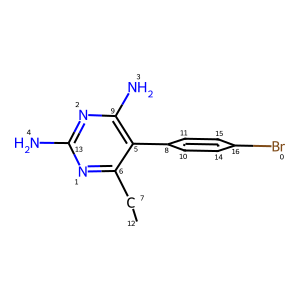

In [14]:

# Load ligand
mod_ligand_Br = Chem.MolFromMolFile("modified_ligand/pyrimethamine_Br_modified.sdf")

# Calculate properties
molecular_weight = Descriptors.MolWt(mol)
logP = Crippen.MolLogP(mol)

print(f"Molecular Weight: {molecular_weight:.2f} g/mol")
print(f"LogP: {logP:.2f}")

mod_ligand_Br

In [15]:
# Load original pyrimethamine
original = Chem.MolFromMolFile("ligands/pyrimethamine.sdf")

# Original properties
original_MW = Descriptors.MolWt(original)
original_LogP = Crippen.MolLogP(original)

# Modified properties
modified_MW = Descriptors.MolWt(mod_ligand_Br)
modified_LogP = Crippen.MolLogP(mod_ligand_Br)

print("Original Pyrimethamine")
print(f"MW   : {original_MW:.2f} g/mol")
print(f"LogP : {original_LogP:.2f}")

print("\nBrominated Pyrimethamine")
print(f"MW   : {modified_MW:.2f} g/mol")
print(f"LogP : {modified_LogP:.2f}")

print("\nChange")
print(f"ΔMW   : {modified_MW - original_MW:+.2f} g/mol")
print(f"ΔLogP : {modified_LogP - original_LogP:+.2f}")

Original Pyrimethamine
MW   : 248.72 g/mol
LogP : 2.52

Brominated Pyrimethamine
MW   : 293.17 g/mol
LogP : 2.63

Change
ΔMW   : +44.45 g/mol
ΔLogP : +0.11


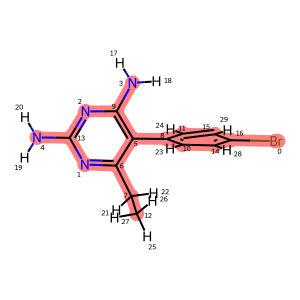

In [16]:
from rdkit import Chem
from rdkit.Chem import AllChem
import os

Chem.SanitizeMol(mod_ligand_Br)
# 2. Add hydrogen atoms
mod_ligand_BrH = Chem.AddHs(mod_ligand_Br)
# 3. Constrained embedding
# Keeps the heavy atoms close to their original positions
# while allowing the added hydrogens to adopt reasonable positions.

constrained_Br = AllChem.ConstrainedEmbed(
    mod_ligand_BrH,
    mod_ligand_Br,
    useTethers=True
)

# Display the embedded molecule
constrained_Br

## Why use constrained embedding?
<div style="background-color: #DCEEFF; padding: 20px; border-radius: 12px;">
Because our modified molecule is based on an existing 3D structure, constrained embedding helps preserve the original heavy-atom geometry while allowing the newly introduced atoms, particularly hydrogen atoms, to be placed in reasonable positions.

This provides a suitable starting structure for subsequent geometry optimization and molecular docking.
EmbedRMS = 0.051 Å

This is very small, meaning the constrained embedding kept the modified molecule's heavy-atom structure extremely close to the original geometry.

In [17]:
# Check whether MMFF parameters are available
if AllChem.MMFFHasAllMoleculeParams(constrained_Br):
# Optimize molecule
    result = AllChem.MMFFOptimizeMolecule(constrained_Br)
    if result == 0:
        print("✓ MMFF94 optimization converged successfully")
    else:
        print("⚠ Optimization reached the maximum number of iterations")
else:
    print("⚠ MMFF94 parameters are not available for this molecule")

✓ MMFF94 optimization converged successfully


In [18]:
#Create output directory
os.makedirs("modified_ligand", exist_ok=True)
# Save optimized molecule
output_file = "modified_ligand/pyrimethamine_Br_optimized.sdf"
writer = Chem.SDWriter(output_file)
writer.write(constrained_Br)
writer.close()
print(f"✓ Optimized molecule saved to: {output_file}")

✓ Optimized molecule saved to: modified_ligand/pyrimethamine_Br_optimized.sdf


#### generating smiles

In [19]:
from rdkit import Chem
from pathlib import Path

for f in Path("ligands").glob("*.sdf"):
    mol = Chem.MolFromMolFile(str(f))
    if mol:
        print(f"{f.name}: {Chem.MolToSmiles(mol)}")

pyrimethamine.sdf: CCc1nc(N)nc(N)c1-c1ccc(Cl)cc1


In [20]:
from rdkit import Chem
from pathlib import Path
import requests
import pandas as pd
import time
ligand_dir = Path("ligands")
categories = [
    "physicochemical", "medchem", "absorption",
    "distribution", "metabolism", "excretion",
    "toxicity", "tox21", "toxicityrule"
]
results = []
for file in ligand_dir.glob("*.sdf"):
    mol = Chem.MolFromMolFile(str(file))
    if mol is None:
        print(f"Skipped: {file.name}")
        continue
    smiles = Chem.MolToSmiles(mol)
    r = requests.post(
        "https://admetlab3.scbdd.com/api/single/admet",
        json={"SMILES": smiles}
    )
    result = r.json()
    if result.get("status") != "success":
        print(f"Failed: {file.name}")
        continue
    data = result["data"]["data"]
    row = {
        "Ligand": file.stem,
        "SMILES": smiles
    }
    for category in categories:
        for item in data.get(category, []):
            row[item["name"]] = item.get("value")
    results.append(row)
    print(f"Done: {file.name}")
    time.sleep(0.25)
df = pd.DataFrame(results)
display(df)
df.to_csv("ADMETlab3_results.csv", index=False)

Done: pyrimethamine.sdf


,Ligand,SMILES,MW,Vol,Dense,nHA,nHD,nRot,nRing,MaxRing,...,SR-MMP,SR-p53,Acute_Aquatic_Toxicity,Genotoxic_Carcinogenicity_Mutagenicity,NonGenotoxic_Carcinogenicity,Skin_Sensitization,LD50_oral,NonBiodegradable,SureChEMBL,Toxicophores
0,pyrimethamine,CCc1nc(N)nc(N)c1-c1ccc(Cl)cc1,248.08,242.37472,1.023539,4.0,4.0,2.0,2.0,6.0,...,0.110544,0.51346,1,5,1,2,1,1,1,1


In [21]:
! conda env export --from-history > vina_environment.yml